# Lab 2: EDA and Conversion Funnel Analysis
**DS 4115 - Marketing Analytics**  
Mushfiqur Rahman | ID: 0152330090 | Section: BB

## Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
print("setup done")

setup done


## 1. Making the session data

In [2]:
np.random.seed(42)
n = 5000

sess_ids = [f"sess_{i:04d}" for i in range(1, n + 1)]
users = [f"user_{np.random.randint(1000, 2000)}" for _ in range(n)]
device = np.random.choice(["desktop", "mobile", "tablet"], size=n, p=[0.5, 0.4, 0.1])

start = np.ones(n, dtype=int)
cart = np.random.choice([0, 1], size=n, p=[0.7, 0.3])
# only people who added to cart can buy
buy = np.where(cart == 1, np.random.choice([0, 1], size=n, p=[0.4, 0.6]), 0)

pv = np.random.poisson(lam=3, size=n) + 1
tos = pv * np.random.randint(20, 60, size=n)

df = pd.DataFrame({
    "session_id": sess_ids,
    "user_id": users,
    "device_category": device,
    "session_start_flag": start,
    "add_to_cart_flag": cart,
    "purchase_flag": buy,
    "page_views": pv,
    "time_on_site_sec": tos
})

# knocking out some values so there is something to clean later
df.loc[np.random.choice(n, 50), "time_on_site_sec"] = np.nan

df.to_csv("ga4_sample_session_logs.csv", index=False)
df.head()

,session_id,user_id,device_category,session_start_flag,add_to_cart_flag,purchase_flag,page_views,time_on_site_sec
0,sess_0001,user_1102,tablet,1,0,0,5,155.0
1,sess_0002,user_1435,desktop,1,0,0,3,171.0
2,sess_0003,user_1860,tablet,1,0,0,2,110.0
3,sess_0004,user_1270,desktop,1,0,0,4,140.0
4,sess_0005,user_1106,desktop,1,1,0,4,80.0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   session_id          5000 non-null   str    
 1   user_id             5000 non-null   str    
 2   device_category     5000 non-null   str    
 3   session_start_flag  5000 non-null   int64  
 4   add_to_cart_flag    5000 non-null   int64  
 5   purchase_flag       5000 non-null   int64  
 6   page_views          5000 non-null   int64  
 7   time_on_site_sec    4950 non-null   float64
dtypes: float64(1), int64(4), str(3)
memory usage: 312.6 KB


## 2. Funnel

In [4]:
total = df["session_id"].nunique()
n_cart = df[df["add_to_cart_flag"] == 1]["session_id"].nunique()
n_buy = df[df["purchase_flag"] == 1]["session_id"].nunique()

funnel = pd.DataFrame({
    "Funnel Step": ["1. Session Start", "2. Add to Cart", "3. Purchase"],
    "User Sessions": [total, n_cart, n_buy]
})
funnel["Conversion Rate (%)"] = funnel["User Sessions"] / total * 100

# drop off from the step before it
funnel["Step Drop-off (%)"] = (1 - funnel["User Sessions"] / funnel["User Sessions"].shift(1)) * 100
print(funnel.round(2))

        Funnel Step  User Sessions  Conversion Rate (%)  Step Drop-off (%)
0  1. Session Start           5000                100.0                NaN
1    2. Add to Cart           1470                 29.4              70.60
2       3. Purchase            905                 18.1              38.44


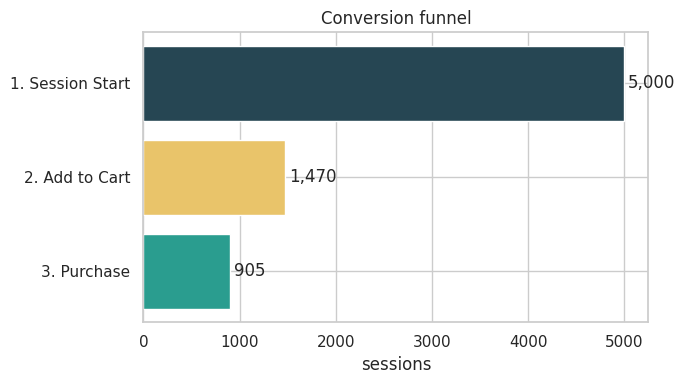

In [5]:
plt.figure(figsize=(7, 4))
bars = plt.barh(funnel["Funnel Step"][::-1], funnel["User Sessions"][::-1], color=["#2a9d8f", "#e9c46a", "#264653"])
for b, v in zip(bars, funnel["User Sessions"][::-1]):
    plt.text(v + 40, b.get_y() + b.get_height() / 2, f"{v:,}", va="center")
plt.xlabel("sessions")
plt.title("Conversion funnel")
plt.tight_layout()
plt.savefig("funnel.png", dpi=200)
plt.show()

## 3. Cleaning

In [6]:
print(df.isnull().sum())

session_id             0
user_id                0
device_category        0
session_start_flag     0
add_to_cart_flag       0
purchase_flag          0
page_views             0
time_on_site_sec      50
dtype: int64


In [7]:
med = df["time_on_site_sec"].median()
print("median time on site:", med)

df["time_on_site_sec"] = df["time_on_site_sec"].fillna(med)
df = df.dropna(subset=["session_id"])
df["device_category"] = df["device_category"].str.lower().str.strip()

print("missing values left:", df.isnull().sum().sum())

median time on site: 144.0
missing values left: 0


## 4. EDA

In [8]:
# quick look at conversion by device
by_dev = df.groupby("device_category").agg(
    sessions=("session_id", "count"),
    cart_rate=("add_to_cart_flag", "mean"),
    buy_rate=("purchase_flag", "mean"),
    avg_pv=("page_views", "mean"),
    avg_time=("time_on_site_sec", "mean")
).round(3)
by_dev

,sessions,cart_rate,buy_rate,avg_pv,avg_time
device_category,,,,,
desktop,2547,0.296,0.186,4.003,157.757
mobile,1958,0.289,0.176,4.071,161.224
tablet,495,0.303,0.176,3.883,152.370


In [9]:
cols = ["session_start_flag", "add_to_cart_flag", "purchase_flag", "page_views", "time_on_site_sec"]
corr = df[cols].corr()
print(corr.round(3))

                    session_start_flag  add_to_cart_flag  purchase_flag  \
session_start_flag                 NaN               NaN            NaN   
add_to_cart_flag                   NaN             1.000          0.728   
purchase_flag                      NaN             0.728          1.000   
page_views                         NaN            -0.011         -0.001   
time_on_site_sec                   NaN             0.002          0.004   

                    page_views  time_on_site_sec  
session_start_flag         NaN               NaN  
add_to_cart_flag        -0.011             0.002  
purchase_flag           -0.001             0.004  
page_views               1.000             0.804  
time_on_site_sec         0.804             1.000  


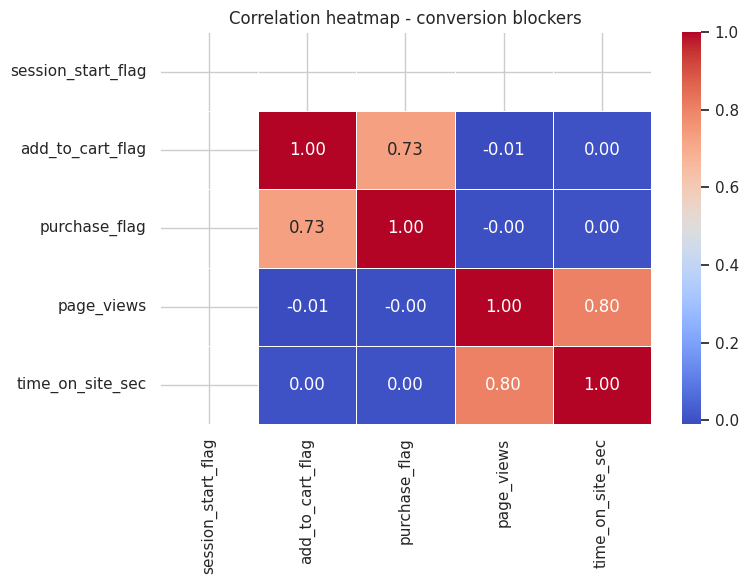

In [10]:
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation heatmap - conversion blockers", fontsize=12)
plt.tight_layout()
plt.savefig("heatmap.png", dpi=200)
plt.show()

## Notes
- Only about 30% of sessions add something to the cart, so the biggest drop is between session start and add to cart.
- `session_start_flag` is 1 for every row, so it has no variance and its correlations show up empty (NaN) in the heatmap.
- `purchase_flag` is tied to `add_to_cart_flag` (r about 0.73) because you can't buy without a cart. Page views and time on site are close to 0 with purchase, which makes sense since this data is random.
- `time_on_site_sec` and `page_views` are strongly correlated because time is built from page views.